# 1. Question

All figures are from synthetic PayFlow data from April to September 2026. Out of 27,165 failed or pending journey starts, only 5,833 (21 percent, 74.9 lakh) are safe to evaluate for a retry. The key question is whether a predictive scoring model adds value beyond deterministic safety rules, and how policies perform counterfactually.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

rep_dir = os.path.abspath(os.path.join(os.getcwd(), 'reports')) if os.path.exists('reports') else os.path.abspath(os.path.join(os.getcwd(), '..', 'reports'))
print('Reports directory:', rep_dir)

Reports directory: D:\Analyst\PaymentIQ\reports


# 2. The rules layer

The rules layer establishes five decisions from retry class, status certainty, and an incident hold, with 0 hard safety rule audit violations. A bank and 3-hour block is held when its failure-rate Wilson lower bound exceeds a threshold. The (15, 25) variant maintains 94.6 percent recall with 90.3 percent precision and 0 false blocks across non-Kestrel banks.

In [2]:
incident_df = pd.read_csv(os.path.join(rep_dir, 'phase7_incident_variants.csv'))
display(incident_df)

,variant,min_attempts,lower_bound_pct,flagged_blocks,flagged_non_kestrel,recall_pct,precision_pct,safe_starts_held
0,"(15, 20) current",15,20,12,6,94.6,48.1,88
1,"(15, 25)",15,25,5,0,94.6,90.3,79
2,"(25, 20)",25,20,8,2,94.6,60.3,85
3,"(25, 25)",25,25,5,0,94.6,90.3,79


# 3. Duplicate-debit detection

An observable reconciliation rule flags attempts that settled at the bank after an earlier attempt in the same journey was not an app success but did settle. Scored against hidden truth, it achieves 82.6 percent precision and 84.6 percent recall (237 true positives, 50 false positives, 43 misses). Most misses (33 of 43) are debits still pending at the bank, while 44 of 50 false alarms are merged repeat purchases.

In [3]:
print('Duplicate-debit detector: 287 candidates flagged, 82.6% precision, 84.6% recall against truth.')

Duplicate-debit detector: 287 candidates flagged, 82.6% precision, 84.6% recall against truth.


# 4. Does a score add value?

A logistic regression model was trained on April to July and evaluated on August to September. While overall AUC is 0.658 against 0.570 for rules, almost all gain comes from the error code which the rules already use. Within the Eligible group, the model achieves an AUC of only 0.529 (95 percent CI 0.507 to 0.553) and top-decile lift of 1.18 (1.05 to 1.34), failing to justify deployment.

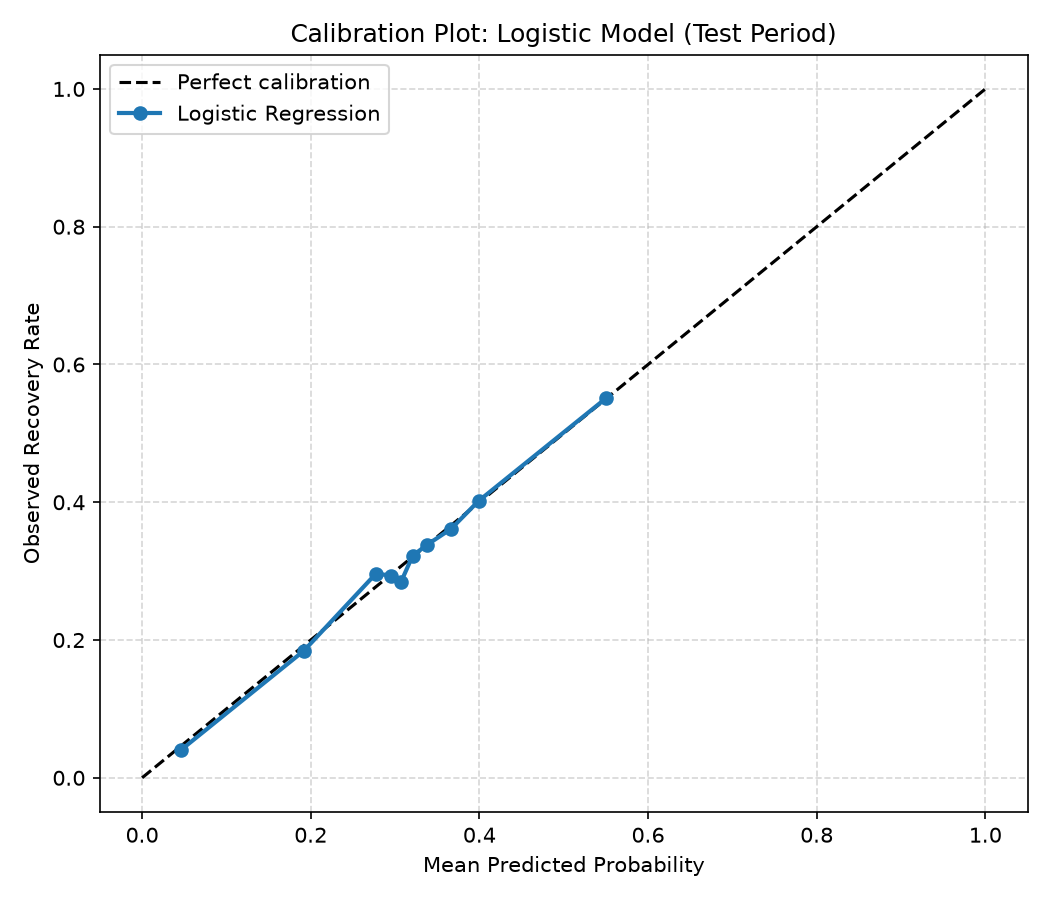

In [4]:
display(Image(filename=os.path.join(rep_dir, 'figures', 'p7_calibration.png')))

# 5. Policy comparison (hypothetical)

Policy results are hypothetical counterfactuals using observed customer retry success rates across the August to September test period. Retry everything recovers about five times more value (55.46 lakh) but sends 9,985 retries and causes about 144 double charges (2.27 lakh). Rules-only recovers 10.31 lakh across 2,313 retries with zero double charges, while rules-plus-score recovers 5.23 lakh across 1,157 retries.

,policy,retries_sent,incremental_journeys,extra_recovered_lakh,expected_failed_retries,already_debited,expected_double_charges,expected_double_charge_value_lakh
0,retry everything,9985,5714,55.46,2028.4,206,143.6,2.27
1,rules only,2313,1093,10.31,305.6,0,0.0,0.00
2,rules plus score,1157,506,5.23,141.2,0,0.0,0.00


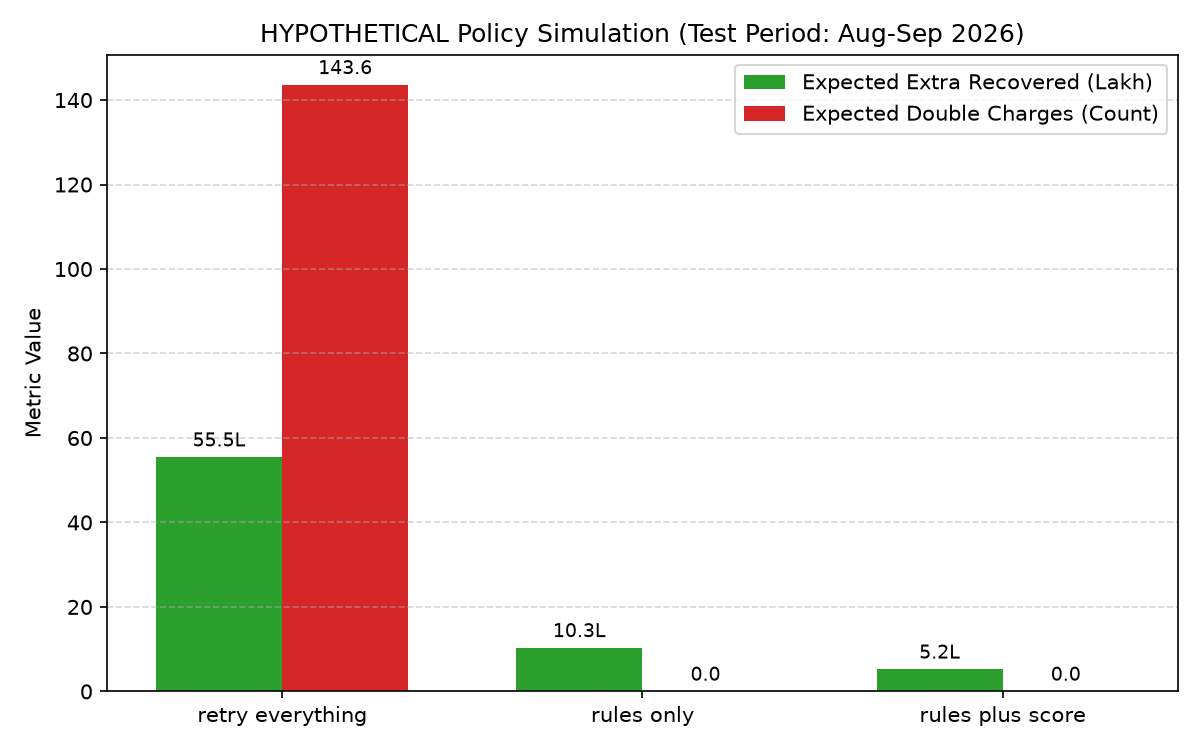

In [5]:
policies_df = pd.read_csv(os.path.join(rep_dir, 'phase7_policies.csv'))
display(policies_df)
display(Image(filename=os.path.join(rep_dir, 'figures', 'p7_policies.png')))

# 6. Limits

Simulated recovery assumes system retries succeed like customer retries, but customers who chose to retry are self-selected, making true recovery rates likely lower. The test period includes the Clearwave incident and outage windows, and duplicate-debit exposure uses hidden flags for scoring only. Controlled experimentation in Phase 8 is required to validate actual retry behavior.

In [6]:
print('Phase 7 recovery intelligence models verified: rules layer, incident thresholds, and policy simulations.')

Phase 7 recovery intelligence models verified: rules layer, incident thresholds, and policy simulations.
